# Segregation-Definition Sensitivity Analyses

## Purpose

This notebook examines whether the age-group comparison of whole-brain network segregation changes when we use the alternative segregation definitions already specified in the project's analysis plan.


## Goal

The goal is to calculate all four predefined segregation measures, verify that the primary calculation reproduces the saved results, and compare the adjusted elderly-minus-young differences using the same eligible participants for every definition.

The primary definition remains `seg_z_positive`. The analysis is cross-sectional and exploratory, with no individual-level head-motion adjustment. It cannot establish causal effects or within-person change with aging.

## Research Question

**Does the recorded-sex-adjusted elderly-minus-young difference in whole-brain system segregation depend on Fisher transformation or negative-edge handling?**

## Data Sources

- `data/external/Curvature-FCN-Aging/DATA/FCM/`
- `data/external/Curvature-FCN-Aging/DATA/cohort_information.tsv`
- `data/interim/participant_alignment_table.csv`
- `data/interim/schaefer200_7networks_labels.tsv`
- `data/processed/network_segregation_results.tsv`
- `data/processed/network_segregation_provenance.tsv`




## Import the Required Tools

We will use `pathlib` to locate project files, `pandas` to load and summarize tables, and `matplotlib` to display the adjusted cohort differences.

The remaining imports will support checksums, software-version records, and the final analysis provenance.


In [68]:
# Import the shared calculation, validation, and comparison functions
import hashlib
import importlib
import json
import platform
import subprocess
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


### Import the Reusable Project Functions

We will reuse the existing participant-identifier and atlas-validation functions together with the network and sensitivity-analysis functions in `src/lemon_connectivity/`.

These functions handle the calculations and validation. The notebook will call them in sequence, display aggregate results, and explain how those results should be interpreted.


In [69]:
# Import the existing validation and sensitivity-analysis functions
from lemon_connectivity.atlas import parse_schaefer_label, validate_atlas_annotations
from lemon_connectivity.identifiers import add_canonical_participant_id
from lemon_connectivity.networks import SEGREGATION_DEFINITIONS
from lemon_connectivity.sensitivity import (
    AGE_GROUP_FORMULA,
    EDGE_POLICY_VERSION,
    calculate_segregation_sensitivities,
    compare_sensitivity_models,
    prepare_sensitivity_analysis,
    select_sensitivity_inputs,
    sha256_file,
    summarize_sensitivity_eligibility,
    verify_primary_inputs,
    verify_primary_replication,
)


## Confirm the Segregation Definitions

The four definitions were specified in `docs/ANALYSIS_PLAN.md` under `edge-policy-v1`. We will evaluate every definition and retain the original primary choice.

| Definition | Transformation | Negative Edges | Role |
|---|---|---|---|
| `seg_z_positive` | Fisher z | Replaced with zero; zeros remain in the means | Primary |
| `seg_r_positive` | Raw correlation | Replaced with zero; zeros remain in the means | Sensitivity |
| `seg_z_signed` | Fisher z | Retained with their signs | Sensitivity |
| `seg_r_signed` | Raw correlation | Retained with their signs | Sensitivity |

Each definition will start from the original signed correlation matrix. Fisher transformation will be applied once to off-diagonal values, and self-connections will be excluded from all summaries.

The same ROI labels and within-network and between-network masks will be used throughout. Every unique upper-triangle edge will contribute once to its corresponding pooled mean, including edges replaced with zero. No additional density threshold will be introduced.

The segregation score is:

$$
S = \frac{W-B}{W}
$$

where $W$ is the pooled within-network mean and $B$ is the pooled between-network mean.

Under every definition, the score will be recorded as unavailable when $W \leq 10^{-12}$. Negative, zero, and near-zero within-network means will receive separate calculation statuses. Computable values of $W$ and $B$ will remain in the participant record.

Defined negative scores and signed scores above one will be retained without clipping. Fisher definitions reject exact off-diagonal correlations of −1 or +1 before negative edges are replaced with zero; raw-correlation definitions allow those endpoints.


## Locate the Project Root

The project root is the directory containing `pyproject.toml`. We will locate it by checking the current working directory and its parent directories.

All input and output paths will then be constructed relative to this location, so the notebook can be launched from the project root or the notebooks directory.


In [70]:
# Resolve paths from either the repository root or the notebooks directory
repo_root = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "pyproject.toml").is_file()
    ),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Run this notebook inside the project repository")


## Define the Input Paths

We will identify the original FCM directory and the five existing tables needed for this analysis: cohort metadata, participant alignment, atlas labels, primary segregation results, and primary provenance.

These paths point to the validated local files from the preceding workflow.


In [71]:
# Define the existing FCM directory and input-table paths
source_dir = repo_root / "data/external/Curvature-FCN-Aging/DATA"
fcm_dir = source_dir / "FCM"
input_paths = {
    "cohort": source_dir / "cohort_information.tsv",
    "alignment": repo_root / "data/interim/participant_alignment_table.csv",
    "atlas": repo_root / "data/interim/schaefer200_7networks_labels.tsv",
    "primary_results": repo_root / "data/processed/network_segregation_results.tsv",
    "primary_provenance": repo_root
    / "data/processed/network_segregation_provenance.tsv",
}


### Verify the Required Input Files

Before loading the tables, we will confirm that every required file exists.

A missing file will stop execution so that the preceding notebook or data-preparation step can be completed before proceeding.


In [72]:
# Confirm that all required input tables are available
for name, path in input_paths.items():
    if not path.is_file():
        raise FileNotFoundError(
            f"Required {name} input is missing; run the preceding notebooks"
        )


### Define the Output Directories

Participant-level results will be saved in the existing `data/processed/` directory. Aggregate tables and figures will be saved in `results/generated/`.



In [73]:
# Set the local participant-output and aggregate-output directories
processed_dir = repo_root / "data/processed"
generated_dir = repo_root / "results/generated"
generated_dir.mkdir(parents=True, exist_ok=True)


## Record the Software Versions

We will record the Python and package versions used for this run, together with the edge-policy version and the four definition identifiers.

These details will also be included in the saved provenance so that the calculation can be traced to its software environment.


In [74]:
# Record software versions and confirm the selected policy
software_versions = {"python": platform.python_version()}
software_versions.update(
    {
        name: importlib.metadata.version(name)
        for name in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]
    }
)
display(pd.Series(software_versions, name="version").to_frame())
print("Edge policy:", EDGE_POLICY_VERSION)
print("Definitions:", ", ".join(SEGREGATION_DEFINITIONS))


,version
python,3.14.3
numpy,2.5.2
pandas,3.0.5
scipy,1.18.1
statsmodels,0.14.6
matplotlib,3.11.1


Edge policy: edge-policy-v1
Definitions: seg_z_positive, seg_r_positive, seg_z_signed, seg_r_signed


## Load the Primary Results and Provenance

We will load the participant-level segregation results and the provenance record saved by Notebook 07.

The saved result table defines the fixed QC-retained participant inventory, including records with unavailable primary scores. Participant identifiers will be preserved as strings.


In [75]:
# Read local inputs without displaying participant records
primary_results = pd.read_csv(
    input_paths["primary_results"],
    sep="\t",
    dtype={"canonical_id": "string"},
)
primary_provenance = pd.read_csv(input_paths["primary_provenance"], sep="\t")


### Load the Alignment and Cohort Metadata

The alignment table links participant identifiers to their FCM filenames. The cohort metadata provide the recorded cohort and sex categories used in the age-group model.

We will load these tables using the same local sources as the preceding analysis.


In [76]:
# Load the participant alignment and cohort metadata
alignment = pd.read_csv(input_paths["alignment"], dtype={"canonical_id": "string"})
cohort = pd.read_csv(input_paths["cohort"], sep="\t", dtype={"sub_id": "string"})


### Create Canonical Participant IDs

The cohort metadata use `sub_id`, while the primary results and alignment table use `canonical_id`.

We will use the existing identifier utility to add a separate canonical ID column while preserving the original source identifiers. The shared validation functions will check those IDs before merging the participant records.


In [77]:
# Add canonical IDs while preserving the original participant identifiers
cohort = add_canonical_participant_id(cohort)


## Load and Validate the Atlas Labels

We will load the validated Schaefer-200 label table and use the existing parser to recover the network identifiers needed by the atlas validator.

The validator checks the complete 200-ROI annotation table. We will then arrange the canonical network labels in the original ROI-index order so they correspond to the positions in every connectivity matrix.


In [78]:
# Load the atlas and validate the ROI-to-network correspondence
atlas = pd.read_csv(input_paths["atlas"], sep="\t")

atlas_validation = atlas.copy()
atlas_validation["network_id"] = [
    parse_schaefer_label(f"7Networks_{hemisphere}_{parcel}")["network_id"]
    for hemisphere, parcel in zip(
        atlas["hemisphere"], atlas["parcel_name"], strict=True
    )
]
validate_atlas_annotations(atlas_validation)
roi_networks = atlas.sort_values("roi_index")["canonical_network"].to_numpy()


## Recover the Fixed QC Participant Inventory

We will recover one FCM filename for every participant in Notebook 07's saved result table. The existing identifier utilities will check that each filename corresponds to its canonical participant ID.

The filenames will be resolved against the local FCM directory. This avoids relying on absolute paths saved on another computer and preserves the earlier QC inventory without silently changing its exclusions.


In [79]:
# Recover the FCM file for every participant in the saved primary inventory
participant_files = select_sensitivity_inputs(primary_results, alignment, fcm_dir)


### Verify the Primary Input Provenance

Before calculating alternative definitions, we will check the saved primary policy, denominator rule, participant count, and source checksums.

The checksums must match the exact FCM inventory and atlas used by Notebook 07. A mismatch will stop execution so the difference can be investigated before proceeding.


In [80]:
# Verify that the primary policy and source inputs remain consistent
primary_input_hashes = verify_primary_inputs(
    primary_provenance, participant_files, input_paths["atlas"], repo_root
)
print("Fixed QC-retained participants:", len(participant_files))
print("Expected participant-definition records:", 4 * len(participant_files))
print("Primary policy, input checksums, and inventory counts match.")


Fixed QC-retained participants: 225
Expected participant-definition records: 900
Primary policy, input checksums, and inventory counts match.


## Calculate Segregation Under Each Definition

We will load each retained participant's FCM file once using the existing validated loader and reconstruct the connectivity matrix using the existing project function.

Each of the four definitions will receive that original signed matrix. The same network labels, masks, pooling rule, and denominator guard will be used for every definition.

The result table will contain four attempted records per retained participant. If the verified inventory contains 225 participants, this will produce 900 records. Unavailable scores and calculation failures will remain in the table with their reasons.

Positive-edge density will also be recorded before transformation. It will describe the input and will not be used to select edges or participants.


In [81]:
# Calculate and save the complete participant-definition ledger locally
sensitivity_ledger = calculate_segregation_sensitivities(
    participant_files, roi_networks
)


### Save the Participant-Level Sensitivity Results

We will save the complete participant-by-definition result table under `data/processed/`.

The table includes the within-network mean, between-network mean, segregation score, edge counts, and calculation status. It will remain local and will not be displayed as participant-level notebook output.


In [82]:
# Save all participant-definition records to the ignored local data directory
ledger_path = processed_dir / "segregation_sensitivity_results.tsv"
sensitivity_ledger.to_csv(ledger_path, sep="\t", index=False)


### Validate the Saved Sensitivity Results

We will read the saved table back and compare it with the in-memory results.

This check covers the recorded values, missing scores, reasons, edge counts, and row ordering. Small floating-point differences introduced by writing and reading a text file are allowed within the stated tolerances.


In [83]:
# Verify the saved ledger, including NaNs, reasons, counts, and row ordering
saved_ledger = pd.read_csv(
    ledger_path,
    sep="\t",
    dtype={"canonical_id": "string"},
)
saved_ledger["calculation_reason"] = saved_ledger["calculation_reason"].fillna("")
pd.testing.assert_frame_equal(
    saved_ledger,
    sensitivity_ledger,
    check_dtype=False,
    check_exact=False,
    rtol=1e-10,
    atol=1e-12,
)
print("Saved and verified participant-definition records:", len(saved_ledger))


Saved and verified participant-definition records: 900


## Reproduce the Saved Primary Calculation

Before interpreting the alternatives, we will compare the recalculated `seg_z_positive` results with Notebook 07's saved primary results.

Participant identifiers, calculation statuses, and edge counts must match exactly. The within-network means, between-network means, and segregation scores must agree within `rtol=1e-10` and `atol=1e-12`, with unavailable values matching as unavailable.

These tolerances concern numerical reproduction and do not change the denominator eligibility rule. A failed comparison will stop execution without replacing the saved primary results.


In [84]:
# Verify primary replication before any age-group sensitivity model
replication_summary = verify_primary_replication(sensitivity_ledger, primary_results)
display(replication_summary)


,measure,matches,max_absolute_difference
0,within_mean,True,8.326673e-17
1,between_mean,True,9.714451e-17
2,system_segregation,True,5.551115e-17


**Interpretation:** Complete after running this section. State whether the primary calculation reproduced the saved results and report the maximum absolute differences shown in the table. Investigate any failure before continuing to the age-group comparison.


## Define the Eligible Analysis Samples

We will attach cohort and recorded-sex information to every participant-definition record and apply the eligibility criteria used in Notebook 08.

Eligible records must have:

- a cohort of `young` or `elderly`;
- a recorded sex category of `female` or `male`;
- a successfully calculated, finite segregation score; and
- matched participant alignment.

Duplicate identifiers or missing participant rows will stop the merge. Unknown or missing cohort and sex values will be marked as ineligible without imputation.

The complete analysis table will retain the eligibility flags for every attempted record and will be saved locally.


In [85]:
# Preserve eligibility flags for every attempted participant-definition record
analysis_ledger = prepare_sensitivity_analysis(sensitivity_ledger, cohort, alignment)
analysis_path = processed_dir / "segregation_sensitivity_analysis.tsv"
analysis_ledger.to_csv(analysis_path, sep="\t", index=False)


### Summarize Eligibility and Calculation Status

We will report the number of attempted, calculated, unavailable, and eligible records for each definition. The calculation-status table will show why any scores are unavailable.

Participants can fail more than one criterion, so individual failure counts should not be summed to obtain the total number excluded.


In [86]:
# Summarize eligibility and calculation outcomes for each definition
eligibility_summary = summarize_sensitivity_eligibility(analysis_ledger)
status_counts = pd.crosstab(
    analysis_ledger["definition"], analysis_ledger["calculation_status"]
).reindex(SEGREGATION_DEFINITIONS, fill_value=0)
display(eligibility_summary)
display(status_counts)


,definition,attempted,calculated,unavailable_score,invalid_or_missing_cohort,invalid_or_missing_sex,eligible_for_definition,common_sample,eligible_but_not_common,common_young,common_elderly
0,seg_z_positive,225,225,0,0,0,225,225,0,153,72
1,seg_r_positive,225,225,0,0,0,225,225,0,153,72
2,seg_z_signed,225,225,0,0,0,225,225,0,153,72
3,seg_r_signed,225,225,0,0,0,225,225,0,153,72


calculation_status,calculated
definition,
seg_z_positive,225
seg_r_positive,225
seg_z_signed,225
seg_r_signed,225


### Establish the Common Eligible Sample

The main comparison will use the same participants under all four definitions. A participant will enter this common sample only when eligible under every definition.

We will also record the number eligible for the primary definition before this restriction. Comparing the full-primary and common-sample primary models later will help distinguish changes caused by sample restriction from changes caused by the segregation definition.


In [87]:
# Identify the common sample and count additional restrictions on the primary sample
common_records = analysis_ledger.loc[analysis_ledger["in_common_sample"]]
common_count = common_records["canonical_id"].nunique()
primary_full_count = int(
    eligibility_summary.loc[
        eligibility_summary["definition"].eq("seg_z_positive"),
        "eligible_for_definition",
    ].iloc[0]
)
print("Common eligible participants:", common_count)
print(
    "Primary-eligible participants outside the common sample:",
    primary_full_count - common_count,
)


Common eligible participants: 225
Primary-eligible participants outside the common sample: 0


**Interpretation:** Complete after running this section. Report the fixed QC inventory, the number eligible under each definition, and the number in the common sample. Explain any unavailable scores or additional exclusions from the common sample using the aggregate summaries.


## Describe Segregation in the Common Sample

We will summarize the segregation scores separately by definition and cohort, using the same common eligible participants throughout.

The table will report the sample size, mean, standard deviation, minimum, and maximum. These are descriptive summaries; the adjusted regression models will provide the planned elderly-minus-young estimates.

Signed scores may be negative or exceed one. We will inspect their range without trimming or clipping values.


In [88]:
# Show only aggregate outcomes and sample counts
common_group_summary = (
    common_records.groupby(["definition", "cohort"])["system_segregation"]
    .agg(n="count", mean="mean", sd="std", minimum="min", maximum="max")
    .reset_index()
)
display(common_group_summary)


,definition,cohort,n,mean,sd,minimum,maximum
0,seg_r_positive,elderly,72,0.639854,0.067288,0.422472,0.762737
1,seg_r_positive,young,153,0.645013,0.058671,0.449568,0.776119
2,seg_r_signed,elderly,72,0.810249,0.127735,0.437565,1.026950
3,seg_r_signed,young,153,0.788852,0.114253,0.459931,1.062149
4,seg_z_positive,elderly,72,0.661704,0.063976,0.458097,0.778687
5,seg_z_positive,young,153,0.667961,0.054986,0.486344,0.795660
6,seg_z_signed,elderly,72,0.818286,0.119143,0.471783,1.020883
7,seg_z_signed,young,153,0.799544,0.105455,0.500687,1.052486


### Summarize the Common Sample by Cohort and Sex

We will describe the composition of the common sample by cohort and recorded sex.

Because every definition uses the same participants, one set of demographic counts describes all four comparison models.


In [89]:
# Summarize the cohort and recorded-sex composition of the common sample
common_demographics = (
    common_records.loc[common_records["definition"].eq("seg_z_positive")]
    .groupby(["cohort", "sex"])
    .size()
    .rename("n")
    .reset_index()
)
display(common_demographics)


,cohort,sex,n
0,elderly,female,36
1,elderly,male,36
2,young,female,44
3,young,male,109


## Specify the Statistical Model

We will retain the model specified for Issue #13: ordinary least squares regression of `system_segregation` on cohort and recorded sex.

The young cohort and female sex category will serve as the reference groups. The estimate of interest is the recorded-sex-adjusted elderly-minus-young difference.

Inference will use HC3 heteroskedasticity-robust standard errors, a t-based 95% confidence interval, and a two-sided t-test. P-values will be unadjusted sensitivity summaries. These related models are not independent replications or a set of new confirmatory discoveries.

All four definitions will be reported. No new covariates, outlier exclusions, or alternative model will be selected from the results, and `seg_z_positive` will remain primary regardless of significance.


### Fit and Report the Adjusted Models

The first four result rows will compare the four definitions on their common eligible sample. A separate `primary_full_reference` row will repeat the original primary model using all primary-eligible participants.

The table will report sample sizes, the adjusted difference, HC3 standard error, 95% confidence interval, two-sided p-value, and model status.

Every predefined model will retain a result row even if it cannot be estimated. An empty common sample, a rank-deficient design, unit leverage that prevents HC3 inference, or nonfinite uncertainty will receive an explicit reason. No replacement model will be fitted automatically.


In [90]:
# Estimate elderly-minus-young differences with the fixed sex-adjusted HC3 model
model_results = compare_sensitivity_models(analysis_ledger)
display(model_results)
print("Formula:", AGE_GROUP_FORMULA)
print("Inference: HC3, use_t=True, 95% CI, two-sided unadjusted p-values.")


,definition,sample,role,edge_policy_version,comparison,n_total,n_young,n_elderly,adjusted_difference,hc3_robust_se,ci_95_lower,ci_95_upper,p_value_two_sided,residual_df,model_status,model_reason
0,seg_z_positive,common,primary,edge-policy-v1,elderly_minus_young_adjusted_for_recorded_sex,225,153,72,-0.004286,0.008990,-0.022003,0.013430,0.633997,222.0,estimated,
1,seg_r_positive,common,sensitivity,edge-policy-v1,elderly_minus_young_adjusted_for_recorded_sex,225,153,72,-0.002950,0.009477,-0.021626,0.015726,0.755859,222.0,estimated,
2,seg_z_signed,common,sensitivity,edge-policy-v1,elderly_minus_young_adjusted_for_recorded_sex,225,153,72,0.023603,0.016634,-0.009177,0.056383,0.157306,222.0,estimated,
3,seg_r_signed,common,sensitivity,edge-policy-v1,elderly_minus_young_adjusted_for_recorded_sex,225,153,72,0.026730,0.017869,-0.008485,0.061946,0.136109,222.0,estimated,
4,seg_z_positive,primary_full_reference,primary,edge-policy-v1,elderly_minus_young_adjusted_for_recorded_sex,225,153,72,-0.004286,0.008990,-0.022003,0.013430,0.633997,222.0,estimated,


Formula: system_segregation ~ C(cohort, Treatment(reference='young')) + C(sex, Treatment(reference='female'))
Inference: HC3, use_t=True, 95% CI, two-sided unadjusted p-values.


**Interpretation:** Complete after running this section. Report the adjusted elderly-minus-young estimate and 95% confidence interval for every definition on the common sample. Compare the `primary_full_reference` row with Notebook 08 and, if the samples differ, compare the two primary rows before attributing changes to the segregation definition.


### Prepare the Adjusted-Difference Plot

We will select the four common-sample model rows and arrange them in the predefined order, with the primary definition first.

The full-primary reference will remain in the results table and will not be mixed into this common-sample figure.


In [91]:
# Plot all four prespecified definitions in a fixed order
common_models = model_results.loc[model_results["sample"].eq("common")].set_index(
    "definition"
)
plot_labels = [
    "Positive Fisher z (primary)",
    "Positive raw r",
    "Signed Fisher z",
    "Signed raw r",
]


### Visualize the Adjusted Cohort Differences

The forest plot will display the adjusted elderly-minus-young estimate and its 95% confidence interval for each definition. The vertical line at zero represents no adjusted cohort difference.

Negative estimates indicate lower segregation in the elderly group. Unestimable models will remain labelled in the figure, with their reasons available in the table.

The intervals describe uncertainty around each estimate. Their overlap or nonoverlap is not a formal test of differences between definitions. The figure will be saved as PNG and SVG files under the ignored generated-results directory.


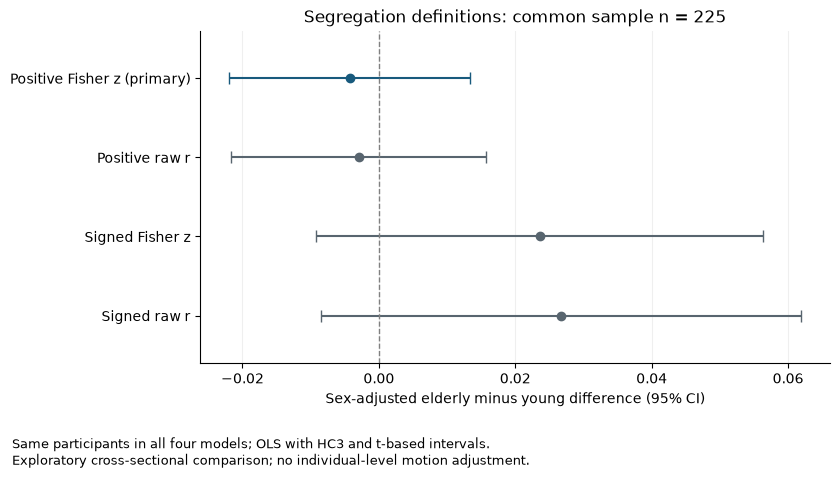

In [92]:
# Plot the four common-sample estimates and their confidence intervals
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for position, definition in enumerate(SEGREGATION_DEFINITIONS):
    row = common_models.loc[definition]
    if row["model_status"] == "estimated":
        estimate = row["adjusted_difference"]
        ax.errorbar(
            estimate,
            position,
            xerr=[[estimate - row["ci_95_lower"]], [row["ci_95_upper"] - estimate]],
            fmt="o",
            capsize=4,
            color="#185A7D" if position == 0 else "#58656F",
        )
    else:
        ax.text(
            0.03,
            position,
            "Not estimable; see table",
            transform=ax.get_yaxis_transform(),
        )
ax.axvline(0, linestyle="--", color="0.5", linewidth=1)
ax.set_yticks(range(4), labels=plot_labels)
ax.set_ylim(3.6, -0.6)
ax.set_xlabel("Sex-adjusted elderly minus young difference (95% CI)")
ax.set_title(f"Segregation definitions: common sample n = {common_count}")
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
fig.text(
    0.02,
    0.02,
    "Same participants in all four models; OLS with HC3 and t-based intervals.\n"
    "Exploratory cross-sectional comparison; no individual-level motion adjustment.",
    fontsize=9,
)
fig.tight_layout(rect=(0, 0.11, 1, 1))
figure_path = generated_dir / "segregation_sensitivity_forest.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
fig.savefig(generated_dir / "segregation_sensitivity_forest.svg", bbox_inches="tight")
plt.show()
plt.close(fig)


**Interpretation:** Complete after running this section. Describe which effect directions and magnitudes are consistent across definitions and which depend on transformation or negative-edge handling. Consider the uncertainty in every estimate; p-value labels alone do not establish robustness or equivalence.


## Save the Aggregate Results

We will save the complete model table, eligibility counts, calculation-status counts, primary-replication check, and common-sample descriptive and demographic tables.

All aggregate tables will remain together under `results/generated/issue14/`. A table or figure may be curated into tracked results only under the repository's results policy, identifying this notebook and Issue #14 as its generating source and approval.


In [93]:
# Save all aggregate results together, without selecting favorable definitions
aggregate_tables = {
    "segregation_sensitivity_models.tsv": model_results,
    "segregation_sensitivity_eligibility.tsv": eligibility_summary,
    "segregation_sensitivity_status_counts.tsv": status_counts.reset_index(),
    "segregation_sensitivity_primary_replication.tsv": replication_summary,
    "segregation_sensitivity_common_group_summary.tsv": common_group_summary,
    "segregation_sensitivity_common_demographics.tsv": common_demographics,
}
for filename, table in aggregate_tables.items():
    table.to_csv(generated_dir / filename, sep="\t", index=False)


## Record the Analysis Provenance

The provenance record will identify the input files, implementation, software versions, policy, statistical model, sample counts, and generated outputs used in this run.

Checksums allow later runs to check whether the underlying files are unchanged. The provenance and participant-level tables will remain in the ignored local data directory.


### Calculate the Implementation Checksums

We will calculate checksums for the network-analysis module, sensitivity-analysis module, and analysis plan.

We will also calculate a checksum of the notebook's source cells. Stored execution outputs are excluded from this checksum, so saving those outputs alone does not alter the recorded notebook source.


In [94]:
# Calculate checksums for the implementation and notebook source
source_paths = [
    repo_root / "src/lemon_connectivity/networks.py",
    repo_root / "src/lemon_connectivity/sensitivity.py",
    repo_root / "docs/ANALYSIS_PLAN.md",
]
source_hashes = {
    path.relative_to(repo_root).as_posix(): sha256_file(path) for path in source_paths
}
notebook_path = repo_root / "notebooks/09_segregation_sensitivity.ipynb"
notebook_document = json.loads(notebook_path.read_text(encoding="utf-8"))
notebook_sources = [
    [cell["cell_type"], "".join(cell["source"])] for cell in notebook_document["cells"]
]
notebook_source_sha256 = hashlib.sha256(
    json.dumps(notebook_sources, ensure_ascii=False).encode("utf-8")
).hexdigest()


### Record the Repository State

We will record the current Git commit and whether the working tree contains uncommitted changes.

If Git information is unavailable, that limitation will be recorded explicitly while the calculation's input and source checksums remain available.


In [95]:
# Record the Git revision and working-tree state when available
try:
    repository_head = subprocess.run(
        ["git", "rev-parse", "HEAD"],
        cwd=repo_root,
        capture_output=True,
        text=True,
        check=True,
    ).stdout.strip()
    working_tree_clean = not bool(
        subprocess.run(
            ["git", "status", "--porcelain"],
            cwd=repo_root,
            capture_output=True,
            text=True,
            check=True,
        ).stdout.strip()
    )
except (OSError, subprocess.CalledProcessError):
    repository_head, working_tree_clean = "unavailable", None


### Assemble the Provenance Record

We will combine the policy, definition identifiers, model specification, sample counts, software versions, and file checksums into one provenance record.

The record will also identify the primary-replication tolerances and the common-sample eligibility rule, making the analysis settings traceable alongside the generated results.


In [96]:
# Collect the analysis settings and input, source, and output checksums
output_paths = [
    ledger_path,
    analysis_path,
    figure_path,
    generated_dir / "segregation_sensitivity_forest.svg",
]
output_paths.extend(generated_dir / name for name in aggregate_tables)
provenance = {
    "issue": 14,
    "generated_at_utc": datetime.now(UTC).isoformat(),
    "edge_policy_version": EDGE_POLICY_VERSION,
    "definitions": list(SEGREGATION_DEFINITIONS),
    "primary_definition": "seg_z_positive",
    "within_mean_denominator_rule": "W <= 1e-12 is undefined",
    "pooling": "equal weights over unique upper-triangle edges; zeros retained",
    "n_rois": len(roi_networks),
    "n_qc_retained": len(participant_files),
    "n_primary_eligible": primary_full_count,
    "n_common_eligible": common_count,
    "model_formula": AGE_GROUP_FORMULA,
    "covariance": "HC3",
    "use_t": True,
    "confidence_level": 0.95,
    "p_value_sidedness": "two-sided",
    "p_value_adjustment": "none",
    "sample_rule": "intersection of eligibility for all four definitions",
    "analysis_status": "exploratory; no individual-level motion adjustment",
    "primary_replication": {"passed": True, "rtol": 1e-10, "atol": 1e-12},
    "primary_input_hashes": primary_input_hashes,
    "input_sha256": {
        path.relative_to(repo_root).as_posix(): sha256_file(path)
        for path in input_paths.values()
    },
    "source_sha256": source_hashes,
    "notebook_source_sha256": notebook_source_sha256,
    "output_sha256": {
        path.relative_to(repo_root).as_posix(): sha256_file(path)
        for path in output_paths
    },
    "software_versions": software_versions,
    "repository_head": repository_head,
    "working_tree_clean": working_tree_clean,
}


### Save the Provenance Record

We will save the provenance as `data/processed/segregation_sensitivity_provenance.json`.

The participant tables will remain local, while the aggregate tables and figures will be available in the generated-results directory for review.


In [97]:
# Save the provenance alongside the local participant-level outputs
provenance_path = processed_dir / "segregation_sensitivity_provenance.json"
provenance_path.write_text(json.dumps(provenance, indent=2) + "\n", encoding="utf-8")
print("Saved aggregate tables and figures under results/generated/.")
print("Participant ledgers and provenance remain under data/processed/.")


Saved aggregate tables and figures under results/generated/.
Participant ledgers and provenance remain under data/processed/.


## Summary

This notebook applies all four segregation definitions already specified under `edge-policy-v1`, checks reproduction of the saved primary calculation, and compares the adjusted age-group estimates on a common eligible sample.

The full-primary reference is reported separately so that sample restriction can be distinguished from changes in the segregation definition. Unavailable scores and unestimable models remain recorded with their reasons.

**Final interpretation:** Complete after running the notebook on the local cohort. State which findings are stable and which are definition-dependent, using all four estimates and their uncertainty. Keep `seg_z_positive` as the primary definition regardless of the alternative results.

The comparison remains exploratory and cross-sectional because individual-level head-motion adjustment is unavailable. The findings cannot establish causal effects or within-person change with aging.

No actual cohort results are prefilled here. The reusable functions and notebook workflow are checked using synthetic inputs in the project's automated tests; the participant results and interpretation come from the local cohort run.
